# 14 — Ablation: Kelompok Fitur dan Tuning MOSSA

Dua pertanyaan, keduanya dijawab dengan **uji statistik terhadap Drift dan terhadap pembanding**, bukan dengan satu angka MAE:

**A. Variabel makro mana yang (kalau ada) membantu?** Empat konfigurasi fitur untuk tiga model wakil otomatis (`wakil_model.json`, notebook 09):

| Kelompok | Fitur eksogen | Sumber hasil |
|---|---|---|
| A_univariat | — | hasil utama (`univariat`) |
| B_global | DXY, S&P 500, US10Y, FFR | notebook ini |
| C_domestik | USD/IDR, IHSG, BI-Rate | notebook ini |
| D_penuh | ketujuh indikator | hasil utama (`multivariat`) |

**B. Apakah tuning MOSSA pada DPformer berguna?** DPformer dengan lr/wd hasil MOSSA (hasil utama) dibandingkan dengan DPformer **tanpa tuning** (lr 1e-3, wd 1e-4; Table 3 jurnal) — seluruh horizon, kedua setup.

Hasil per run disimpan di `results/ablation/runs/` dan dilewati bila sudah valid (aman dilanjutkan). Perkiraan waktu FULL pada CPU 2 thread: sekitar 0,5–1 jam.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

import json
from src.config import ABLATION_GROUPS, ABL_HORIZONS
wakil = A.load_wakil(RES)
reps3 = [wakil['dpformer'], wakil['dl'], wakil['ml']]
ABL_RUNS = os.path.join(RES, 'ablation', 'runs')
os.makedirs(ABL_RUNS, exist_ok=True)
mossa_all = load_mossa(os.path.join(RES, 'mossa_dpformer.json'))
if mossa_all is None:
    raise RuntimeError('MOSSA DPformer belum tersedia. Jalankan notebook 05 terlebih dahulu.')
print('Model yang diablasi (otomatis dari notebook 09):', reps3, '| horizon:', ABL_HORIZONS)
for g, cols in ABLATION_GROUPS.items():
    print(f'  {g:12s}: {cols if cols else "(tanpa eksogen)"}')

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
Model yang diablasi (otomatis dari notebook 09): ['dpformer', 'gru_att', 'adaboost'] | horizon: [5, 20]
  A_univariat : (tanpa eksogen)
  B_global    : ['dxy_ret', 'sp500_ret', 'us10yr_diff', 'ffr_diff']
  C_domestik  : ['usd_idr_ret', 'ihsg_ret', 'bi_rate_diff']
  D_penuh     : ['dxy_ret', 'sp500_ret', 'usd_idr_ret', 'ihsg_ret', 'us10yr_diff', 'ffr_diff', 'bi_rate_diff']


## A. Ablation kelompok fitur

In [2]:
def lr_wd_multi(model):
    """Sama dengan run utama multivariat: DPformer = hasil MOSSA, model lain = default Table 3."""
    if model == 'dpformer':
        lr, wd, _ = mossa_all['multivariat']
        return lr, wd
    return BASE_LR, BASE_WD


def run_abl(g, m, h):
    cols = ABLATION_GROUPS[g]
    if m in ML_MODELS:
        return R.run_ml(p, exo, g, m, h, exo_cols=cols, rev=ML_REV, data_hash=DATA_HASH)
    lr, wd = lr_wd_multi(m)
    return R.run_dl(p, exo, g, m, h, lr=lr, wd=wd, exo_cols=cols, data_hash=DATA_HASH)


GRUP_RUN = ['B_global', 'C_domestik']                       # A dan D = hasil utama
t_ml = [(g, m, h) for g in GRUP_RUN for m in reps3 if m in ML_MODELS for h in ABL_HORIZONS]
t_dl = [(g, m, h) for g in GRUP_RUN for m in reps3 if m not in ML_MODELS for h in ABL_HORIZONS]
c1 = R.run_grid(t_ml, run_abl, ABL_RUNS, rev=ML_REV, data_hash=DATA_HASH)
c2 = R.run_grid(t_dl, run_abl, ABL_RUNS, data_hash=DATA_HASH)
assert c1['gagal'] == 0 and c2['gagal'] == 0, (c1['daftar_gagal'], c2['daftar_gagal'])

RUN  B_global/adaboost/h5 ... OK MAE=29,655 (15.5s)
RUN  B_global/adaboost/h20 ... OK MAE=59,791 (11.6s)
RUN  C_domestik/adaboost/h5 ... OK MAE=30,038 (12.1s)
RUN  C_domestik/adaboost/h20 ... OK MAE=58,945 (11.7s)

Selesai. Baru: 4 (menimpa hasil basi: 0) | sudah ada & valid: 0 | gagal: 0
RUN  B_global/dpformer/h5 ... WARNING:tensorflow:From c:\Users\wildnrfm\Downloads\antam_forecasting\.venv\Lib\site-packages\keras\src\backend\tensorflow\core.py:233: The name tf.placeholder is deprecated. Please use tf.compat.v1.placeholder instead.

OK MAE=30,248 (86.1s, 14 epoch, terbaik=4)
RUN  B_global/dpformer/h20 ... OK MAE=63,708 (109.8s, 20 epoch, terbaik=10)
RUN  B_global/gru_att/h5 ... OK MAE=30,209 (47.5s, 11 epoch, terbaik=1)
RUN  B_global/gru_att/h20 ... OK MAE=64,540 (41.9s, 12 epoch, terbaik=2)
RUN  C_domestik/dpformer/h5 ... OK MAE=30,227 (49.0s, 13 epoch, terbaik=3)
RUN  C_domestik/dpformer/h20 ... OK MAE=63,380 (52.8s, 12 epoch, terbaik=2)
RUN  C_domestik/gru_att/h5 ... OK MAE=31,084

In [3]:
variants = {'A_univariat': ('runs', 'univariat'), 'B_global': ('ablation/runs', 'B_global'),
            'C_domestik': ('ablation/runs', 'C_domestik'), 'D_penuh': ('runs', 'multivariat')}
tbl = A.variant_table(RES, p, variants, reps3, ABL_HORIZONS, ref='A_univariat')
cmp_ = tbl.grup != 'A_univariat'
tbl['q_bh_vs_A'] = np.nan
tbl.loc[cmp_, 'q_bh_vs_A'] = S.bh_fdr(tbl.loc[cmp_, 'p_one_vs_ref'].values, 0.05)[0]
tbl.to_csv(os.path.join(RES, 'ablation_ringkasan.csv'), index=False)

print('Rasio MSE-return terhadap Drift (<1 = lebih baik dari Drift):')
display(tbl.pivot_table(index=['model', 'horizon'], columns='grup', values='rel_mse_ret').reindex(columns=list(variants)).round(4))
print('p-value DM satu-sisi terhadap Drift:')
display(tbl.pivot_table(index=['model', 'horizon'], columns='grup', values='p_one_hln').reindex(columns=list(variants)).round(3))
print('Dibanding univariat (A): rasio MSE-return (<1 = menambah eksogen membantu), p satu-sisi, q-BH (keluarga = semua perbandingan tabel ini):')
display(tbl[cmp_][['model', 'horizon', 'grup', 'rel_mse_vs_ref', 'p_one_vs_ref', 'q_bh_vs_A']].round(4).reset_index(drop=True))
print(f'Perbandingan dengan p<0,05: {int((tbl[cmp_].p_one_vs_ref < 0.05).sum())} dari {int(cmp_.sum())}; lolos BH (FDR 5%): {int((tbl[cmp_].q_bh_vs_A < 0.05).sum())}')

Rasio MSE-return terhadap Drift (<1 = lebih baik dari Drift):


grup              A_univariat  B_global  C_domestik  D_penuh
model    horizon                                            
adaboost 5             0.9867    0.9739      0.9917   0.9701
         20            0.8015    0.8488      0.8209   0.8556
dpformer 5             0.9956    1.0123      1.0032   0.9897
         20            1.0172    1.0464      1.0019   1.0272
gru_att  5             1.0014    1.0031      1.0569   0.9915
         20            0.9796    1.0578      0.9623   1.0585

p-value DM satu-sisi terhadap Drift:


grup              A_univariat  B_global  C_domestik  D_penuh
model    horizon                                            
adaboost 5              0.351     0.111       0.397    0.062
         20             0.094     0.084       0.082    0.085
dpformer 5              0.205     0.831       0.691    0.198
         20             0.980     0.982       0.568    0.881
gru_att  5              0.554     0.578       0.925    0.270
         20             0.135     0.979       0.055    0.965

Dibanding univariat (A): rasio MSE-return (<1 = menambah eksogen membantu), p satu-sisi, q-BH (keluarga = semua perbandingan tabel ini):


,model,horizon,grup,rel_mse_vs_ref,p_one_vs_ref,q_bh_vs_A
0,dpformer,5,B_global,1.0168,0.9003,0.9884
1,dpformer,20,B_global,1.0287,0.9441,0.9884
2,gru_att,5,B_global,1.0018,0.5693,0.9884
3,gru_att,20,B_global,1.0797,0.9884,0.9884
4,adaboost,5,B_global,0.9870,0.2416,0.7814
5,adaboost,20,B_global,1.0590,0.8416,0.9884
6,dpformer,5,C_domestik,1.0076,0.8998,0.9884
7,dpformer,20,C_domestik,0.9850,0.1831,0.7814
8,gru_att,5,C_domestik,1.0555,0.9464,0.9884
9,gru_att,20,C_domestik,0.9823,0.0615,0.7814


Perbandingan dengan p<0,05: 0 dari 18; lolos BH (FDR 5%): 0


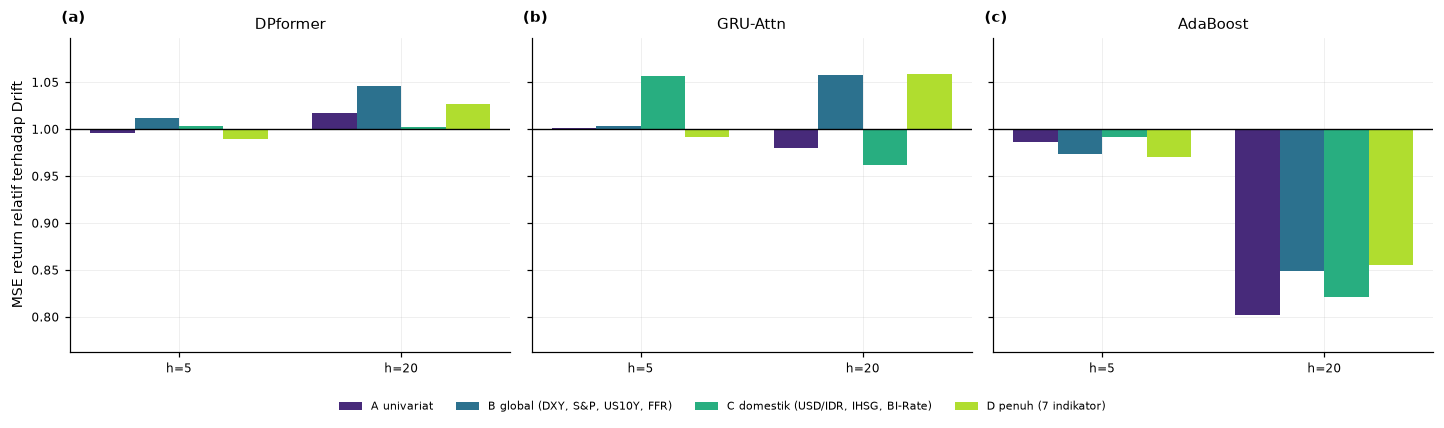

In [4]:
names = {'A_univariat': 'A univariat', 'B_global': 'B global (DXY, S&P, US10Y, FFR)',
         'C_domestik': 'C domestik (USD/IDR, IHSG, BI-Rate)', 'D_penuh': 'D penuh (7 indikator)'}
fig = P.fig_ablation(tbl, reps3, ABL_HORIZONS, list(variants), group_names=names)
simpan(fig, 'fig_ablation_fitur')

**Cara membaca.** Batang di atas garis 1,0 = lebih buruk daripada Drift. Bila menambah variabel makro tidak menurunkan rasio secara konsisten (dan uji terhadap univariat tidak signifikan setelah koreksi BH), kesimpulan yang jujur adalah **variabel makro lag-1 tidak memberi informasi tambahan yang dapat dibuktikan** untuk return Antam — bukan "multivariat gagal". Lihat notebook 15 untuk pengaruh *waktu informasi*.

## B. DPformer: tuning MOSSA vs tanpa tuning

Seed, arsitektur, data, dan split **sama**; hanya (lr, wd) yang berbeda. Hasil tanpa tuning disimpan dengan label `<setup>_default`.

In [5]:
t_def = [(f'{s}_default', 'dpformer', h) for s in SETUPS for h in HORIZONS]


def run_default(lb, m, h):
    s = lb.replace('_default', '')
    return R.run_dl(p, exo if s == 'multivariat' else None, lb, m, h, lr=BASE_LR, wd=BASE_WD, data_hash=DATA_HASH)


c3 = R.run_grid(t_def, run_default, ABL_RUNS, data_hash=DATA_HASH)
assert c3['gagal'] == 0, c3['daftar_gagal']

RUN  univariat_default/dpformer/h1 ... OK MAE=13,185 (38.9s, 11 epoch, terbaik=1)
RUN  univariat_default/dpformer/h5 ... OK MAE=30,126 (51.0s, 14 epoch, terbaik=4)
RUN  univariat_default/dpformer/h10 ... OK MAE=42,537 (62.6s, 20 epoch, terbaik=10)
RUN  univariat_default/dpformer/h20 ... OK MAE=63,001 (80.8s, 23 epoch, terbaik=13)
RUN  univariat_default/dpformer/h30 ... OK MAE=84,080 (94.5s, 29 epoch, terbaik=19)
RUN  multivariat_default/dpformer/h1 ... OK MAE=13,273 (62.5s, 14 epoch, terbaik=4)
RUN  multivariat_default/dpformer/h5 ... OK MAE=30,068 (53.5s, 13 epoch, terbaik=3)
RUN  multivariat_default/dpformer/h10 ... OK MAE=41,964 (56.8s, 18 epoch, terbaik=8)
RUN  multivariat_default/dpformer/h20 ... OK MAE=63,064 (61.8s, 18 epoch, terbaik=8)
RUN  multivariat_default/dpformer/h30 ... OK MAE=84,045 (71.2s, 18 epoch, terbaik=8)

Selesai. Baru: 10 (menimpa hasil basi: 0) | sudah ada & valid: 0 | gagal: 0


,setup,horizon,lr_MOSSA,wd_MOSSA,MAE_MOSSA,MAE_default,MOSSA_lebih_baik_%,rel_mse_MOSSA_per_default,p_one_MOSSA_lebih_baik,pct_vs_drift_MOSSA,pct_vs_drift_default,q_bh
0,univariat,1,0.0007,0.0084,13220.8562,13185.0121,-0.2719,1.0024,0.6718,0.1982,0.4688,0.9863
1,univariat,5,0.0007,0.0084,30012.3291,30126.2932,0.3783,0.9931,0.0421,0.2539,-0.1248,0.2107
2,univariat,10,0.0007,0.0084,42516.8605,42537.3337,0.0481,1.0008,0.6748,0.3932,0.3452,0.9863
3,univariat,20,0.0007,0.0084,63153.7570,63001.0729,-0.2424,1.0101,0.9719,-0.3189,-0.0764,0.9863
4,univariat,30,0.0007,0.0084,83643.4594,84080.3891,0.5197,0.9847,0.0071,-0.3962,-0.9206,0.0713
5,multivariat,1,0.0009,0.0075,13299.3201,13273.3026,-0.1960,1.0035,0.8862,-0.3941,-0.1977,0.9863
6,multivariat,5,0.0009,0.0075,30072.5029,30068.1133,-0.0146,0.9954,0.1876,0.0539,0.0685,0.6252
7,multivariat,10,0.0009,0.0075,42138.6341,41963.5218,-0.4173,1.0120,0.9863,1.2793,1.6895,0.9863
8,multivariat,20,0.0009,0.0075,62831.9885,63064.3458,0.3684,0.9998,0.4838,0.1922,-0.1769,0.9863
9,multivariat,30,0.0009,0.0075,84269.0067,84044.9855,-0.2665,1.0055,0.8830,-1.1470,-0.8781,0.9863


Rata-rata keunggulan MOSSA terhadap default: -0.009% (MAE); MOSSA lebih baik pada 4 dari 10 kombinasi; p<0,05: 2; lolos BH: 0


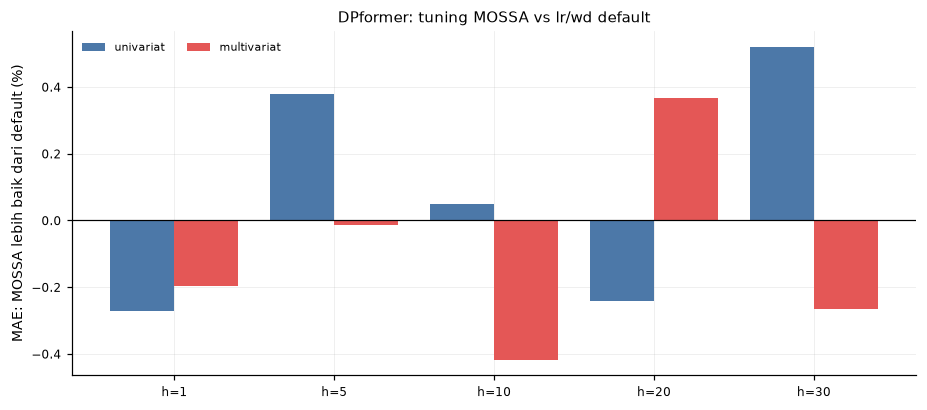

In [6]:
rows = []
for s in SETUPS:
    t = A.variant_table(RES, p, {'MOSSA': ('runs', s), 'default': ('ablation/runs', f'{s}_default')}, ['dpformer'], HORIZONS, ref='default')
    mo, de = t[t.grup == 'MOSSA'].set_index('horizon'), t[t.grup == 'default'].set_index('horizon')
    for h in HORIZONS:
        if h not in mo.index or h not in de.index:
            continue
        rows.append({'setup': s, 'horizon': h, 'lr_MOSSA': mossa_all[s][0], 'wd_MOSSA': mossa_all[s][1],
                     'MAE_MOSSA': mo.loc[h, 'MAE'], 'MAE_default': de.loc[h, 'MAE'],
                     'MOSSA_lebih_baik_%': 100 * (de.loc[h, 'MAE'] - mo.loc[h, 'MAE']) / de.loc[h, 'MAE'],
                     'rel_mse_MOSSA_per_default': mo.loc[h, 'rel_mse_vs_ref'], 'p_one_MOSSA_lebih_baik': mo.loc[h, 'p_one_vs_ref'],
                     'pct_vs_drift_MOSSA': mo.loc[h, 'pct_vs_drift'], 'pct_vs_drift_default': de.loc[h, 'pct_vs_drift']})
mv = pd.DataFrame(rows)
mv['q_bh'] = S.bh_fdr(mv.p_one_MOSSA_lebih_baik.values, 0.05)[0]
mv.to_csv(os.path.join(RES, 'ablation_mossa_vs_default.csv'), index=False)
display(mv.round(4))
print(f'Rata-rata keunggulan MOSSA terhadap default: {mv["MOSSA_lebih_baik_%"].mean():+.3f}% (MAE); '
      f'MOSSA lebih baik pada {int((mv["MOSSA_lebih_baik_%"] > 0).sum())} dari {len(mv)} kombinasi; '
      f'p<0,05: {int((mv.p_one_MOSSA_lebih_baik < 0.05).sum())}; lolos BH: {int((mv.q_bh < 0.05).sum())}')
fig = P.fig_bars_by_horizon(mv, 'MOSSA_lebih_baik_%', HORIZONS, SETUPS, 'setup',
                            'MAE: MOSSA lebih baik dari default (%)', title='DPformer: tuning MOSSA vs lr/wd default',
                            colors={'univariat': '#4c78a8', 'multivariat': '#e45756'})
simpan(fig, 'fig_mossa_vs_default')

**Cara membaca.** Selisih kecil (di bawah ±1% MAE) dengan p-value tidak signifikan berarti tuning MOSSA **tidak menghasilkan perbaikan yang dapat dibedakan dari derau**. Ini temuan yang sah dan harus dilaporkan apa adanya (jurnal acuan melaporkan perbaikan pada data harga dunia dengan sinyal yang lebih kuat). Pemilihan (lr, wd) hanya memakai validasi ber-embargo sehingga tidak ada kebocoran ke uji.